In [1]:
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from sklearn.metrics import mean_absolute_error,mean_squared_error
sys.path.insert(0, r"D:\Ansar\cubeAi\QuantEdge")

from model.kronos import (
    Kronos,
    KronosTokenizer,
    KronosPredictor
)

d:\Ansar\cubeAi\QuantEdge\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
df=pd.read_csv("D:\Ansar\cubeAi\QuantEdge\Data\processed\stocks\ITC.csv")
df.head()

,date,symbol,open,high,low,close,volume
0,2005-04-01,ITC,29.50,30.20,29.22,29.89,20670000.0
1,2005-04-04,ITC,30.08,30.54,29.39,29.82,17080000.0
2,2005-04-05,ITC,30.16,30.38,29.79,29.85,14110000.0
3,2005-04-06,ITC,29.92,30.43,29.83,30.29,9820000.0
4,2005-04-07,ITC,30.38,30.88,30.19,30.39,22890000.0


In [4]:
df['timestamps']=pd.to_datetime(df['date'])
df=df.sort_values(by='timestamps').reset_index(drop=True)


In [7]:
df.head()

,date,symbol,open,high,low,close,volume,timestamps
0,2005-04-01,ITC,29.50,30.20,29.22,29.89,20670000.0,2005-04-01
1,2005-04-04,ITC,30.08,30.54,29.39,29.82,17080000.0,2005-04-04
2,2005-04-05,ITC,30.16,30.38,29.79,29.85,14110000.0,2005-04-05
3,2005-04-06,ITC,29.92,30.43,29.83,30.29,9820000.0,2005-04-06
4,2005-04-07,ITC,30.38,30.88,30.19,30.39,22890000.0,2005-04-07


In [46]:

df["timestamps"] = pd.to_datetime(df["date"])
df = df.sort_values("timestamps").reset_index(drop=True)

device = "cuda" if torch.cuda.is_available() else "cpu"

tokenizer = KronosTokenizer.from_pretrained(
    "NeoQuasar/Kronos-Tokenizer-base"
)
model = Kronos.from_pretrained(
    "NeoQuasar/Kronos-small"
).to(device)

predictor = KronosPredictor(
    model,
    tokenizer,
    device=device
    # max_context=512
)

lookback = 1000
pred_len = 120

x_df = df.iloc[:lookback][
    ["open", "high", "low", "close", "volume"]
].copy()

x_timestamps = df.iloc[:lookback]["timestamps"]


y_timestamps = df.iloc[
    lookback:lookback + pred_len
]["timestamps"]

print("Input shape:", x_df.shape)
print("Input timestamps:", len(x_timestamps))
print("Future timestamps:", len(y_timestamps))

x_df.head()


Input shape: (1000, 5)
Input timestamps: 1000
Future timestamps: 120


,open,high,low,close,volume
0,29.50,30.20,29.22,29.89,20670000.0
1,30.08,30.54,29.39,29.82,17080000.0
2,30.16,30.38,29.79,29.85,14110000.0
3,29.92,30.43,29.83,30.29,9820000.0
4,30.38,30.88,30.19,30.39,22890000.0


In [47]:
forecast_df=predictor.predict(
    df=x_df,
    x_timestamp=x_timestamps,
    y_timestamp=y_timestamps,
    pred_len=pred_len,
    T=0.1,
    top_p=0.9,
    sample_count=1
)

100%|██████████| 120/120 [00:21<00:00,  5.68it/s]


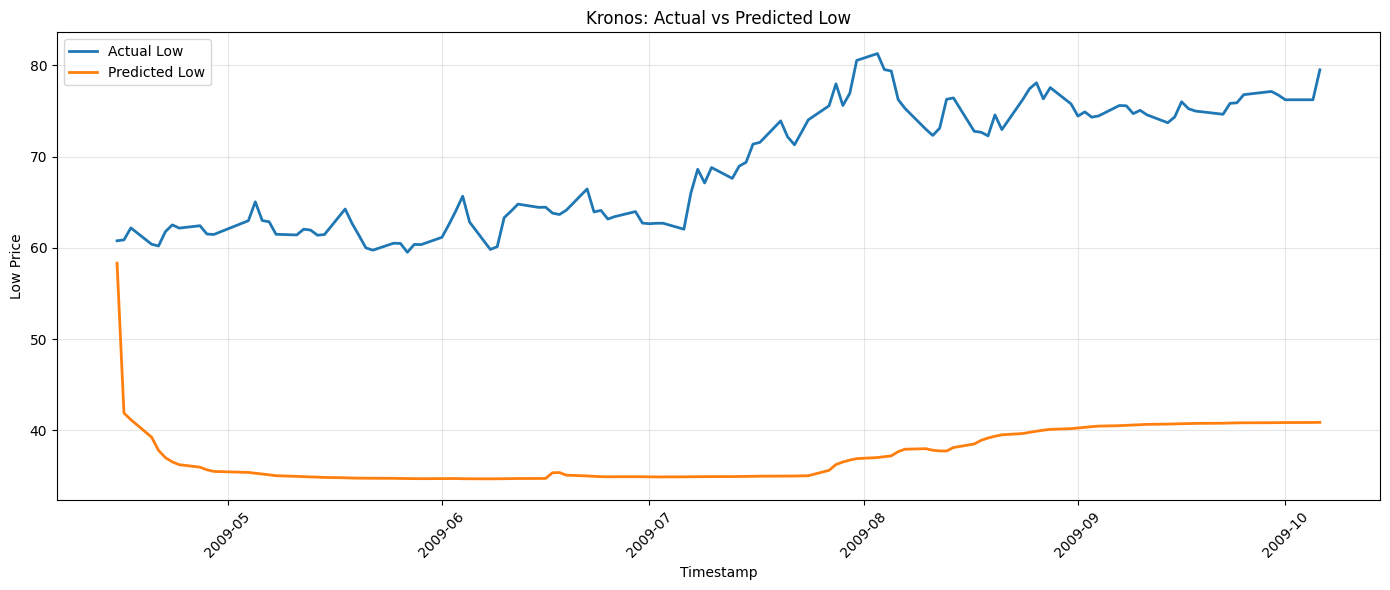

In [48]:
import matplotlib.pyplot as plt
import numpy as np

actual_low=df.iloc[lookback:lookback+pred_len]["low"].to_numpy()
predicted_low=forecast_df["low"].to_numpy()


plt.figure(figsize=(14, 6))

plt.plot(
    y_timestamps,
    actual_low,
    label="Actual Low",
    linewidth=2
)

plt.plot(
    y_timestamps,
    predicted_low,
    label="Predicted Low",
    linewidth=2
)

plt.title("Kronos: Actual vs Predicted Low")
plt.xlabel("Timestamp")
plt.ylabel("Low Price")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


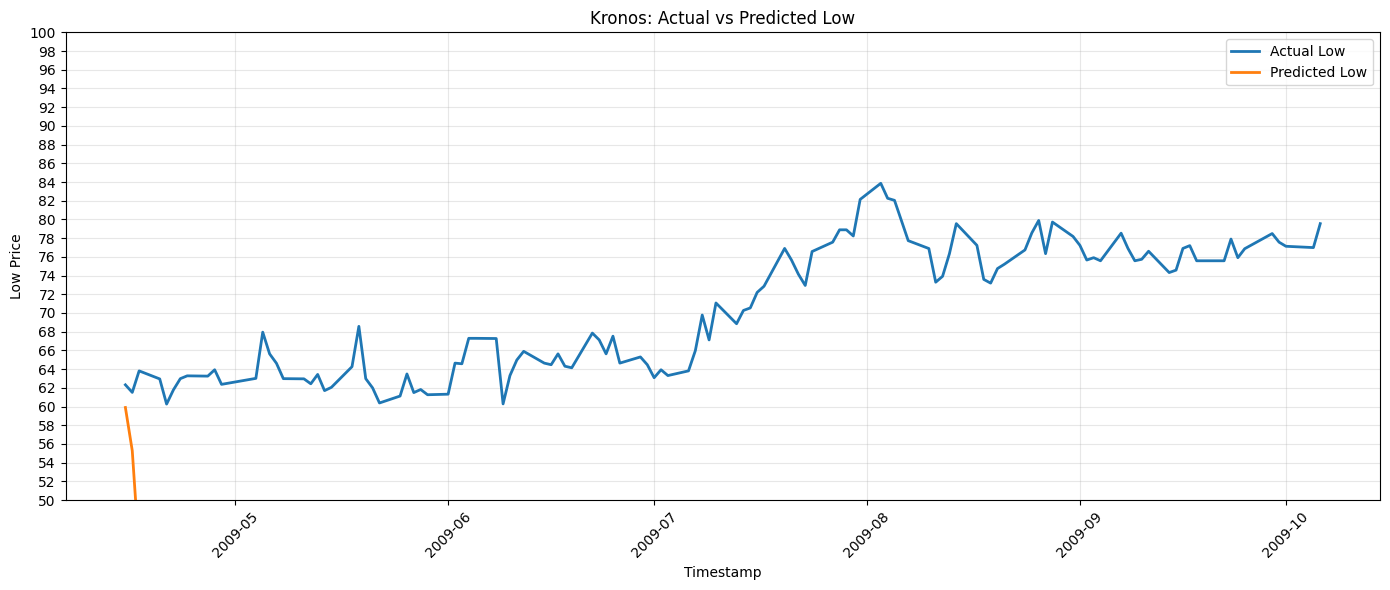

In [49]:
import matplotlib.pyplot as plt
import numpy as np

actual_low=df.iloc[lookback:lookback+pred_len]["open"].to_numpy()
predicted_low=forecast_df["open"].to_numpy()


plt.figure(figsize=(14, 6))

plt.plot(
    y_timestamps,
    actual_low,
    label="Actual Low",
    linewidth=2
)

plt.plot(
    y_timestamps,
    predicted_low,
    label="Predicted Low",
    linewidth=2
)
plt.ylim(50, 100)
plt.yticks(range(50, 101, 2))
plt.title("Kronos: Actual vs Predicted Low")
plt.xlabel("Timestamp")
plt.ylabel("Low Price")
plt.legend()
plt.grid(True, alpha=0.3)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [50]:
print("Forecast columns:")
print(forecast_df.columns.tolist())

print("\nFirst 5 predicted values:")
print(forecast_df[["open", "high", "low", "close"]].head())

print("\nUnique values per column:")
print(forecast_df[["open", "high", "low", "close"]].nunique())

print("\nActual values from test data:")
print(df.iloc[lookback:lookback + pred_len][
    ["open", "high", "low", "close","timestamps"]
].head())

Forecast columns:
['open', 'high', 'low', 'close', 'volume', 'amount']

First 5 predicted values:
                 open       high        low      close
timestamps                                            
2009-04-15  59.895065  60.089256  58.329510  59.526779
2009-04-16  55.276634  55.116058  41.897449  45.320217
2009-04-17  44.346035  45.227982  41.168846  42.397617
2009-04-20  41.294975  41.798824  39.247528  39.844231
2009-04-21  39.172710  39.678585  37.805088  38.239811

Unique values per column:
open     120
high     120
low      120
close    120
dtype: int64

Actual values from test data:
       open   high    low  close timestamps
1000  62.32  63.23  60.78  61.37 2009-04-15
1001  61.51  64.26  60.88  63.54 2009-04-16
1002  63.81  64.27  62.19  62.47 2009-04-17
1003  62.95  63.08  60.40  61.22 2009-04-20
1004  60.26  63.41  60.21  62.53 2009-04-21


In [51]:

import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

actual = df.iloc[lookback:lookback + pred_len]["low"].to_numpy()
predicted = forecast_df["low"].to_numpy()

results = pd.DataFrame({
    "timestamp": df.iloc[lookback:lookback + pred_len]["timestamps"].to_numpy(),
    "actual_low": actual,
    "predicted_low": predicted
})

results["absolute_error"] = np.abs(
    results["actual_low"] - results["predicted_low"]
)

print("Overall MAE:", mean_absolute_error(actual, predicted))
print("Overall RMSE:", np.sqrt(mean_squared_error(actual, predicted)))

print("\nFirst 10 predictions:")
print(results.head(10).round(3).to_string(index=False))

print("\nLast 10 predictions:")
print(results.tail(10).round(3).to_string(index=False))

print("\nError by forecast segment:")
for start in range(0, len(results), 20):
    segment = results.iloc[start:start + 20]
    print(
        f"Rows {start + 1}-{start + len(segment)}: "
        f"MAE = {segment['absolute_error'].mean():.3f}"
    )


Overall MAE: 31.627014340718585
Overall RMSE: 32.166458935011

First 10 predictions:
 timestamp  actual_low  predicted_low  absolute_error
2009-04-15       60.78      58.330002           2.450
2009-04-16       60.88      41.896999          18.983
2009-04-17       62.19      41.168999          21.021
2009-04-20       60.40      39.248001          21.152
2009-04-21       60.21      37.805000          22.405
2009-04-22       61.79      37.004002          24.786
2009-04-23       62.52      36.539001          25.981
2009-04-24       62.17      36.233002          25.937
2009-04-27       62.43      35.959000          26.471
2009-04-28       61.52      35.674000          25.846

Last 10 predictions:
 timestamp  actual_low  predicted_low  absolute_error
2009-09-18       75.00      40.758999          34.241
2009-09-22       74.65      40.780998          33.869
2009-09-23       75.84      40.801998          35.038
2009-09-24       75.91      40.816002          35.094
2009-09-25       76.80      4

In [34]:
import pandas as pd
import numpy as np

# Actual Low values from your original dataset
actual_low = df.iloc[lookback:lookback + pred_len]["open"].reset_index(drop=True)

# Predicted Low values from Kronos
predicted_low = forecast_df["open"].reset_index(drop=True)

# Combine into one DataFrame
comparison_df = pd.DataFrame({
    "Timestamp": y_timestamps.reset_index(drop=True),
    "Actual_Low": actual_low,
    "Predicted_Low": predicted_low
})

# Calculate prediction error
comparison_df["Error"] = (
    comparison_df["Actual_Low"] - comparison_df["Predicted_Low"]
)

comparison_df["Absolute_Error"] = comparison_df["Error"].abs()

# Display the first 20 rows
print(comparison_df.head(20).to_string(index=False))

 Timestamp  Actual_Low  Predicted_Low     Error  Absolute_Error
2006-11-03       62.65      62.783813 -0.133813        0.133813
2006-11-06       62.25      63.068558 -0.818558        0.818558
2006-11-07       63.64      63.200397  0.439603        0.439603
2006-11-08       62.80      63.345230 -0.545230        0.545230
2006-11-09       61.99      63.401276 -1.411276        1.411276
2006-11-10       62.65      63.402889 -0.752889        0.752889
2006-11-13       61.99      63.425861 -1.435861        1.435861
2006-11-14       61.90      63.418148 -1.518148        1.518148
2006-11-15       61.65      63.445194 -1.795194        1.795194
2006-11-16       61.39      63.478512 -2.088512        2.088512
2006-11-17       61.69      63.505371 -1.815371        1.815371
2006-11-20       59.70      63.517223 -3.817223        3.817223
2006-11-21       59.80      63.539921 -3.739921        3.739921
2006-11-22       61.32      63.570290 -2.250290        2.250290
2006-11-23       60.33      63.556335 -3